# Embedding model comparison

Scores computed by `04_evaluate.py` for the seven retrieval methods, on every query in `data/queries.json`, in English and Italian.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RESULTS_DIR = Path("results")
FIGURES_DIR = RESULTS_DIR / "figures"
BASELINES = ["TF-IDF", "BM25"]
SCORE_NAMES = {"ndcg_at_10": "nDCG@10", "precision_at_3": "Precision@3", "mrr_at_10": "MRR@10"}
LANGUAGE_NAMES = {"en": "English", "it": "Italian"}
LANGUAGE_COLORS = {"en": "#2a78d6", "it": "#eb6834"}

summary = pd.read_csv(RESULTS_DIR / "summary.csv")
per_query = pd.read_csv(RESULTS_DIR / "per_query.csv")
methods = list(dict.fromkeys(summary["method"]))
FIGURES_DIR.mkdir(exist_ok=True)

Mean of each score over all queries, per method and language.

In [2]:
summary_table = summary.pivot(index="method", columns="language", values=list(SCORE_NAMES))
summary_table.columns = [
    f"{SCORE_NAMES[score]} {language}" for score, language in summary_table.columns
]
summary_table.loc[methods].round(3)

,nDCG@10 en,nDCG@10 it,Precision@3 en,Precision@3 it,MRR@10 en,MRR@10 it
method,,,,,,
TF-IDF,0.401,0.035,0.426,0.015,0.556,0.036
BM25,0.499,0.019,0.522,0.012,0.676,0.030
sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2,0.429,0.365,0.444,0.383,0.599,0.517
sentence-transformers/paraphrase-multilingual-mpnet-base-v2,0.514,0.452,0.552,0.469,0.633,0.596
intfloat/multilingual-e5-small,0.502,0.248,0.537,0.269,0.715,0.434
intfloat/multilingual-e5-base,0.591,0.234,0.590,0.247,0.732,0.416
BAAI/bge-m3,0.643,0.546,0.633,0.565,0.787,0.739


nDCG@10 by query type. Topic queries are graded against `data/judgements.json`, sequel queries against their one known answer.

In [3]:
ndcg_by_query_type = per_query.pivot_table(
    index="method", columns=["query_type", "language"], values="ndcg_at_10"
)
ndcg_by_query_type.loc[methods].round(3)

query_type                                         sequel         topic       
language                                               en     it     en     it
method                                                                        
TF-IDF                                              0.125  0.107  0.423  0.029
BM25                                                0.129  0.036  0.528  0.017
sentence-transformers/paraphrase-multilingual-M...  0.045  0.000  0.460  0.395
sentence-transformers/paraphrase-multilingual-m...  0.233  0.136  0.536  0.477
intfloat/multilingual-e5-small                      0.098  0.090  0.535  0.261
intfloat/multilingual-e5-base                       0.420  0.329  0.605  0.226
BAAI/bge-m3                                         0.401  0.369  0.663  0.561

The two charts below are also saved as PNG in `results/figures/`.

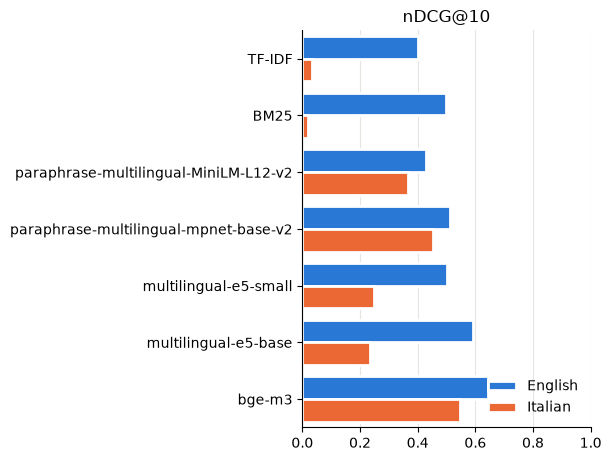

In [4]:
def plot_score(axis, score):
    table = summary.pivot(index="method", columns="language", values=score).loc[methods]
    positions = np.arange(len(methods))
    for offset, language in zip([-0.2, 0.2], table.columns, strict=True):
        axis.barh(
            positions + offset,
            table[language],
            height=0.4,
            color=LANGUAGE_COLORS[language],
            edgecolor="white",
            linewidth=2,
            label=LANGUAGE_NAMES[language],
        )
    axis.set_yticks(positions, [method.split("/")[-1] for method in methods])
    axis.set_ylim(len(methods) - 0.5, -0.5)
    axis.set_xlim(0, 1)
    axis.set_title(SCORE_NAMES[score])
    axis.grid(axis="x", color="#e6e5e0")
    axis.set_axisbelow(True)
    axis.spines[["top", "right"]].set_visible(False)


def save_score_chart(scores, filename):
    figure, axes = plt.subplots(
        1, len(scores), figsize=(6 * len(scores), 4.5), sharey=True, layout="constrained"
    )
    axes = np.atleast_1d(axes)
    for axis, score in zip(axes, scores, strict=True):
        plot_score(axis, score)
    axes[0].legend(loc="lower right", frameon=False)
    figure.savefig(FIGURES_DIR / filename, dpi=200)
    plt.show()


save_score_chart(["ndcg_at_10"], "ndcg_at_10.png")

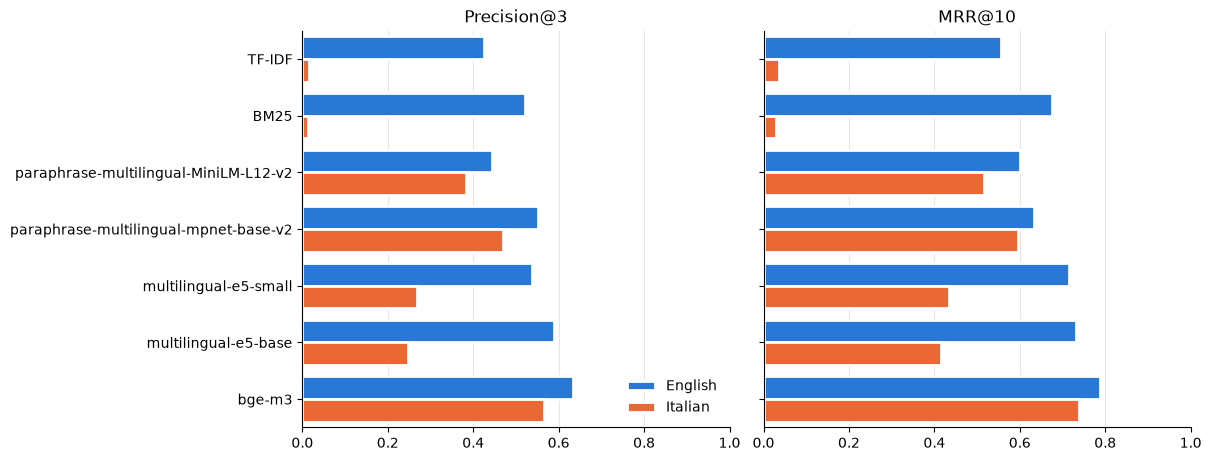

In [5]:
save_score_chart(["precision_at_3", "mrr_at_10"], "precision_at_3_and_mrr_at_10.png")

The recommended model is the embedding model with the highest nDCG@10 averaged equally over English and Italian. TF-IDF and BM25 are shown for comparison only.

In [6]:
mean_ndcg = summary.groupby("method")["ndcg_at_10"].mean().sort_values(ascending=False)
recommended_model = mean_ndcg.drop(BASELINES).idxmax()
print(mean_ndcg.round(3).to_string())
print(f"\nRecommended model: {recommended_model}")

method
BAAI/bge-m3                                                    0.595
sentence-transformers/paraphrase-multilingual-mpnet-base-v2    0.483
intfloat/multilingual-e5-base                                  0.412
sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2    0.397
intfloat/multilingual-e5-small                                 0.375
BM25                                                           0.259
TF-IDF                                                         0.218

Recommended model: BAAI/bge-m3
